# YOLO26 로컬 서비스 노트북 (탐지 + 분할)

사진 한 장(또는 여러 장)을 넣으면 **yolo26n.pt**(박스·클래스·점수)와 **yolo26n-seg.pt**(박스·클래스·점수 + 마스크)로 추론하고,
`conf=0.25`와 `conf=0.50` 결과를 나란히 비교합니다. 웹 화면 없이 노트북만으로 동작합니다.

## 실행 방법 (이 폴더에서)

```powershell
python -m venv --system-site-packages .venv          # 이미 있으면 생략
.\.venv\Scripts\python.exe -m pip install ultralytics ipykernel pandas matplotlib
.\.venv\Scripts\python.exe -m ipykernel install --prefix .venv --name python3   # 이 가상환경을 노트북 커널로 등록
.\.venv\Scripts\python.exe -m nbconvert --to notebook --execute --inplace yolo_service.ipynb
```

(`--system-site-packages` 는 PC에 이미 설치된 torch·numpy·opencv 를 다시 받지 않으려는 선택입니다. `python -m jupyter` 가 아니라 `python -m nbconvert` 로 실행해야 가상환경 커널을 찾습니다.)

또는 노트북을 열고 위에서부터 **Run All** 하면 됩니다.

- **내 사진 넣기**: `inputs/` 폴더에 `.jpg/.png` 를 넣고 다시 실행합니다. 폴더가 비어 있을 때만 샘플 사진(`bus.jpg`)을 내려받습니다.
- **실행 위치**: 이 PC(로컬) · CPU · 인터넷은 모델/샘플 내려받을 때만 사용 (아래 환경 칸에서 실제 값 확인).
- **결과 저장 위치**: `outputs/yolo/` (이미지·JSON·마스크·검토 기록·코드), 기록 파일은 `outputs/yolo/manifest.json`.

## 1. 설정과 선택 이유

| 설정 | 값 | 이유 |
|---|---|---|
| `imgsz` | 640 | 과제 지시값. 사진을 긴 변 640px로 줄여 모델에 넣음(원본 좌표는 자동으로 되돌려 저장됨) |
| `device` | `cpu` | 과제 지시값. 설치된 torch가 CPU 빌드(`+cpu`)라 어차피 GPU를 쓸 수 없음. 장치를 고정해 두면 "어디서 돌렸는지"를 manifest에 정확히 적을 수 있음 |
| `conf` | 0.25, 0.50 | 과제 지시값. 0.25는 느슨(많이 잡힘), 0.50은 엄격(확실한 것만) — 둘의 차이로 "점수 낮은 탐지"를 가려냄 |
| 모델 | `yolo26n`, `yolo26n-seg` | 가장 작은(n) 크기라 CPU에서도 돌릴 수 있음(실제 걸린 시간은 5번 칸 표의 ms). seg는 같은 계열에 마스크가 추가된 모델이라 박스 비교가 가능 |

In [1]:
import json, hashlib, platform, sys, time, subprocess, shutil
from collections import Counter
from datetime import datetime
from importlib.metadata import version
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.utils.downloads import attempt_download_asset

plt.rcParams["font.family"] = ["Malgun Gothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
INPUT_DIR = ROOT / "inputs"
MODEL_DIR = ROOT / "models"
OUT = ROOT / "outputs" / "yolo"
for d in ("images", "json", "masks", "verify", "code"):
    (OUT / d).mkdir(parents=True, exist_ok=True)

IMGSZ = 640
DEVICE = "cpu"
CONFS = (0.25, 0.50)
MODELS = {"det": "yolo26n.pt", "seg": "yolo26n-seg.pt"}
# 입력 폴더가 비었을 때만 내려받는 공개 샘플 (bus: Ultralytics 문서 샘플, coco_*: COCO val2017 이미지)
SAMPLES = {
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "coco_000000000139.jpg": "http://images.cocodataset.org/val2017/000000000139.jpg",
    "coco_000000001000.jpg": "http://images.cocodataset.org/val2017/000000001000.jpg",
}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

def rel(p):
    return Path(p).resolve().relative_to(ROOT.resolve()).as_posix()

RUN_STARTED = datetime.now().astimezone().isoformat(timespec="seconds")
print("설정:", dict(imgsz=IMGSZ, device=DEVICE, confs=CONFS, models=MODELS))

설정: {'imgsz': 640, 'device': 'cpu', 'confs': (0.25, 0.5), 'models': {'det': 'yolo26n.pt', 'seg': 'yolo26n-seg.pt'}}


## 2. 실행 환경 기록

"어디서, 무엇으로 돌렸는가"를 실제 값으로 남깁니다. (PC 이름·사용자 이름은 기록하지 않음)

In [2]:
PKGS = ["ultralytics", "torch", "torchvision", "numpy", "opencv-python", "pillow", "pandas", "matplotlib"]
env = {
    "run_location": "로컬 PC (클라우드 아님)",
    "os": platform.platform(),
    "cpu": platform.processor(),
    "python": sys.version.split()[0],
    "device_used": DEVICE,
    "torch_cuda_available": torch.cuda.is_available(),
    "torch_build": torch.__version__,
    "packages": {p: version(p) for p in PKGS},
}
print(json.dumps(env, ensure_ascii=False, indent=2))

{
  "run_location": "로컬 PC (클라우드 아님)",
  "os": "Windows-10-10.0.19045-SP0",
  "cpu": "Intel64 Family 6 Model 165 Stepping 5, GenuineIntel",
  "python": "3.14.0",
  "device_used": "cpu",
  "torch_cuda_available": false,
  "torch_build": "2.10.0+cpu",
  "packages": {
    "ultralytics": "8.4.208",
    "torch": "2.10.0",
    "torchvision": "0.25.0",
    "numpy": "2.4.2",
    "opencv-python": "4.13.0.92",
    "pillow": "12.0.0",
    "pandas": "3.1.1",
    "matplotlib": "3.11.2"
  }
}


## 3. 모델 준비 (없을 때만 내려받기)

In [3]:
MODEL_DIR.mkdir(exist_ok=True)
models, model_info = {}, {}
for kind, fname in MODELS.items():
    path = MODEL_DIR / fname
    if not path.exists():
        attempt_download_asset(str(path))   # ultralytics 공식 GitHub assets에서 받음
    models[kind] = YOLO(str(path))
    model_info[kind] = {"file": rel(path), "bytes": path.stat().st_size, "sha256": sha256(path),
                        "task": models[kind].task, "n_classes": len(models[kind].names)}
print(json.dumps(model_info, ensure_ascii=False, indent=2))

{
  "det": {
    "file": "models/yolo26n.pt",
    "bytes": 5544453,
    "sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef",
    "task": "detect",
    "n_classes": 80
  },
  "seg": {
    "file": "models/yolo26n-seg.pt",
    "bytes": 6719965,
    "sha256": "361fbfabab285c3237700b6bb91d7ecfa602cd945fffda8dbe1242829b71e73f",
    "task": "segment",
    "n_classes": 80
  }
}


## 4. 입력 사진 확인

`inputs/` 안의 사진을 모두 처리합니다. 파일마다 크기와 SHA-256을 기록해, 나중에 "같은 파일로 돌린 결과인지" 확인할 수 있게 합니다.

In [4]:
INPUT_DIR.mkdir(exist_ok=True)
images = sorted(p for p in INPUT_DIR.iterdir() if p.suffix.lower() in IMG_EXT)
input_source = {}
if not images:
    import urllib.request
    images = []
    for name, url in SAMPLES.items():
        target = INPUT_DIR / name
        urllib.request.urlretrieve(url, target)
        images.append(target)
        input_source[name] = url
        print("inputs/ 가 비어 있어 샘플 사진을 내려받음:", url)

input_info = []
for p in images:
    im = cv2.imread(str(p))
    if im is None:
        print("읽기 실패(건너뜀):", p.name)
        continue
    h, w = im.shape[:2]
    input_info.append({"file": rel(p), "bytes": p.stat().st_size, "sha256": sha256(p),
                       "width": w, "height": h, "source_url": input_source.get(p.name)})
images = [ROOT / i["file"] for i in input_info]
pd.DataFrame(input_info)[["file", "width", "height", "bytes", "source_url"]]

,file,width,height,bytes,source_url
0,inputs/bus.jpg,810,1080,137419,None
1,inputs/coco_000000000139.jpg,640,426,161811,None
2,inputs/coco_000000001000.jpg,640,480,321136,None


## 5. 추론 + 저장

사진 × 모델 × conf 조합마다 아래를 저장합니다.

- `outputs/yolo/images/` : 박스·클래스·점수(와 마스크)를 그린 결과 이미지
- `outputs/yolo/json/` : 박스 좌표 JSON (원본 사진 픽셀 기준 `box_xyxy` = 왼쪽 위 x,y / 오른쪽 아래 x,y)
- `outputs/yolo/masks/` : seg 모델의 객체별 마스크 PNG (원본 크기, 흰색=객체). 모델이 준 윤곽선(폴리곤)을 원본 크기에 채워서 만듦

In [5]:
def tag(c):
    return f"conf{int(round(c * 100)):03d}"

runs = {}       # (이미지이름, kind, conf) -> {"dets": [...], "ms": ...}
timings = []
for img in images:
    orig = cv2.imread(str(img))
    H, W = orig.shape[:2]
    for kind in MODELS:
        for conf in CONFS:
            t0 = time.perf_counter()
            r = models[kind].predict(str(img), imgsz=IMGSZ, device=DEVICE, conf=conf, verbose=False)[0]
            ms = (time.perf_counter() - t0) * 1000
            assert tuple(r.orig_shape) == (H, W), "결과 좌표 기준 크기가 원본과 다름"
            stem = f"{img.stem}__{kind}__{tag(conf)}"
            cv2.imwrite(str(OUT / "images" / f"{stem}.jpg"), r.plot())

            dets = []
            for i, b in enumerate(r.boxes):
                x1, y1, x2, y2 = b.xyxy[0].tolist()
                d = {"id": i, "class_id": int(b.cls), "class_name": r.names[int(b.cls)],
                     "score": round(float(b.conf), 4),
                     "box_xyxy": [round(v, 1) for v in (x1, y1, x2, y2)]}
                if r.masks is not None:
                    poly = r.masks.xy[i]
                    m = np.zeros((H, W), np.uint8)
                    if len(poly) >= 3:
                        cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 255)
                    mfile = OUT / "masks" / f"{stem}__{i}.png"
                    cv2.imwrite(str(mfile), m)
                    d["mask_file"] = rel(mfile)
                    d["mask_area_px"] = int((m > 0).sum())
                dets.append(d)

            doc = {"image": rel(img), "image_size": {"width": W, "height": H}, "model": MODELS[kind],
                   "settings": {"imgsz": IMGSZ, "device": DEVICE, "conf": conf},
                   "n_detections": len(dets), "detections": dets}
            (OUT / "json" / f"{stem}.json").write_text(json.dumps(doc, ensure_ascii=False, indent=2), encoding="utf-8")
            runs[(img.name, kind, conf)] = {"dets": dets, "ms": ms, "stem": stem, "size": (W, H)}
            timings.append({"image": img.name, "model": MODELS[kind], "conf": conf,
                            "detections": len(dets), "ms": round(ms, 1)})
pd.DataFrame(timings)

,image,model,conf,detections,ms
0,bus.jpg,yolo26n.pt,0.25,5,1824.2
1,bus.jpg,yolo26n.pt,0.50,5,55.8
2,bus.jpg,yolo26n-seg.pt,0.25,5,184.8
3,bus.jpg,yolo26n-seg.pt,0.50,5,59.7
4,coco_000000000139.jpg,yolo26n.pt,0.25,13,64.7
5,coco_000000000139.jpg,yolo26n.pt,0.50,8,40.3
6,coco_000000000139.jpg,yolo26n-seg.pt,0.25,12,69.6
7,coco_000000000139.jpg,yolo26n-seg.pt,0.50,7,56.8
8,coco_000000001000.jpg,yolo26n.pt,0.25,13,66.9
9,coco_000000001000.jpg,yolo26n.pt,0.50,9,44.8


## 6. conf 0.25 ↔ 0.50 비교

In [6]:
def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

rows, dropped_rows = [], []
for img in images:
    for kind in MODELS:
        lo, hi = runs[(img.name, kind, 0.25)]["dets"], runs[(img.name, kind, 0.50)]["dets"]
        rows.append({"image": img.name, "model": MODELS[kind],
                     "n@0.25": len(lo), "n@0.50": len(hi), "0.25에만 있음": len(lo) - len(hi),
                     "classes@0.25": dict(Counter(d["class_name"] for d in lo)),
                     "classes@0.50": dict(Counter(d["class_name"] for d in hi))})
        for d in lo:
            kept = any(h["class_id"] == d["class_id"] and iou(d["box_xyxy"], h["box_xyxy"]) > 0.9 for h in hi)
            if not kept:
                dropped_rows.append({"image": img.name, "model": MODELS[kind], "class": d["class_name"],
                                     "score": d["score"], "box_xyxy": d["box_xyxy"]})
        # 점검: 0.50 결과는 점수 0.50 이상뿐이어야 하고, 0.25에서 사라진 것은 점수 0.50 미만뿐이어야 함
        assert all(h["score"] >= 0.50 for h in hi)
        assert all(x["score"] < 0.50 for x in dropped_rows if x["image"] == img.name and x["model"] == MODELS[kind])
summary = pd.DataFrame(rows)
display(summary)
print("conf를 0.50으로 올렸을 때 사라진 탐지:")
display(pd.DataFrame(dropped_rows) if dropped_rows else "없음 (두 conf 결과가 같음)")

,image,model,n@0.25,n@0.50,0.25에만 있음,classes@0.25,classes@0.50
0,bus.jpg,yolo26n.pt,5,5,0,"{'bus': 1, 'person': 4}","{'bus': 1, 'person': 4}"
1,bus.jpg,yolo26n-seg.pt,5,5,0,"{'person': 4, 'bus': 1}","{'person': 4, 'bus': 1}"
2,coco_000000000139.jpg,yolo26n.pt,13,8,5,"{'tv': 2, 'chair': 3, 'person': 1, 'clock': 1,...","{'tv': 2, 'chair': 3, 'person': 1, 'clock': 1,..."
3,coco_000000000139.jpg,yolo26n-seg.pt,12,7,5,"{'tv': 2, 'chair': 4, 'person': 1, 'refrigerat...","{'tv': 2, 'chair': 4, 'person': 1}"
4,coco_000000001000.jpg,yolo26n.pt,13,9,4,"{'person': 11, 'tennis racket': 2}",{'person': 9}
5,coco_000000001000.jpg,yolo26n-seg.pt,16,9,7,"{'person': 12, 'tennis racket': 3, 'sports bal...","{'person': 8, 'tennis racket': 1}"


conf를 0.50으로 올렸을 때 사라진 탐지:


,image,model,class,score,box_xyxy
0,coco_000000000139.jpg,yolo26n.pt,vase,0.4387,"[550.0, 300.3, 587.2, 399.1]"
1,coco_000000000139.jpg,yolo26n.pt,potted plant,0.4270,"[333.8, 174.7, 367.5, 219.0]"
2,coco_000000000139.jpg,yolo26n.pt,potted plant,0.3966,"[228.3, 175.9, 267.1, 212.7]"
3,coco_000000000139.jpg,yolo26n.pt,vase,0.2868,"[240.4, 197.5, 252.2, 212.4]"
4,coco_000000000139.jpg,yolo26n.pt,dining table,0.2609,"[292.4, 213.5, 448.7, 298.7]"
5,coco_000000000139.jpg,yolo26n-seg.pt,refrigerator,0.4254,"[489.9, 169.2, 513.8, 285.0]"
6,coco_000000000139.jpg,yolo26n-seg.pt,potted plant,0.4122,"[228.3, 173.5, 266.4, 212.9]"
7,coco_000000000139.jpg,yolo26n-seg.pt,refrigerator,0.3878,"[448.5, 169.0, 506.3, 293.5]"
8,coco_000000000139.jpg,yolo26n-seg.pt,vase,0.3836,"[549.4, 303.7, 586.6, 399.9]"
9,coco_000000000139.jpg,yolo26n-seg.pt,clock,0.2846,"[448.3, 120.6, 461.1, 142.1]"


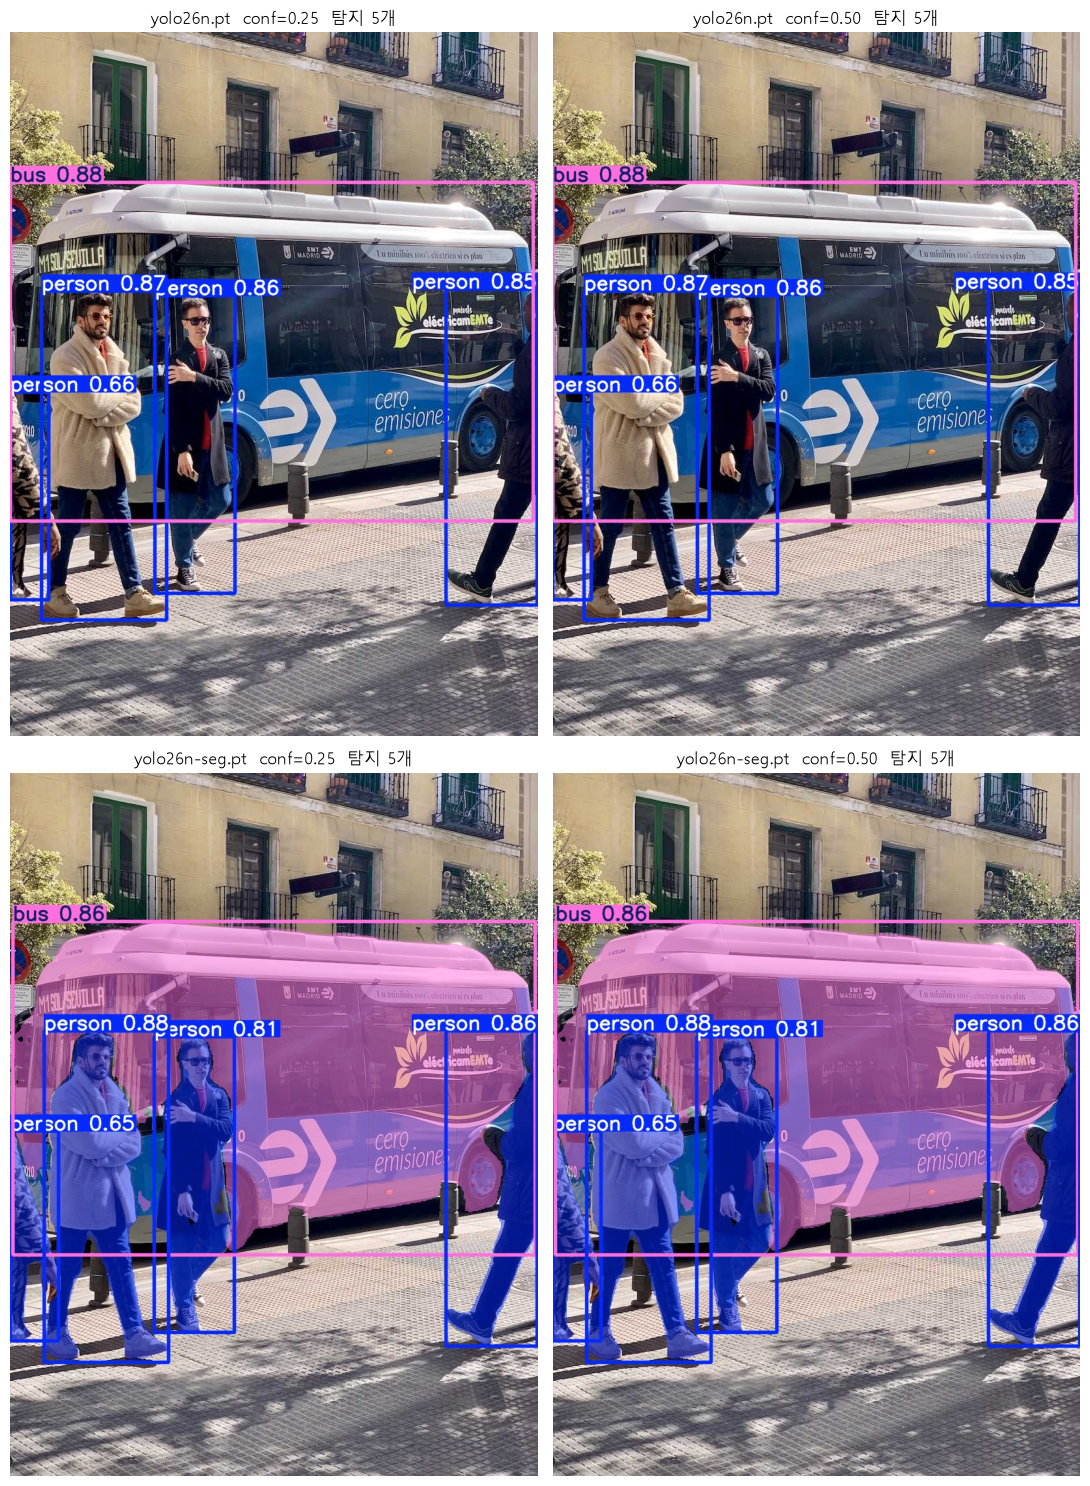

저장: outputs/yolo/comparison__bus.png


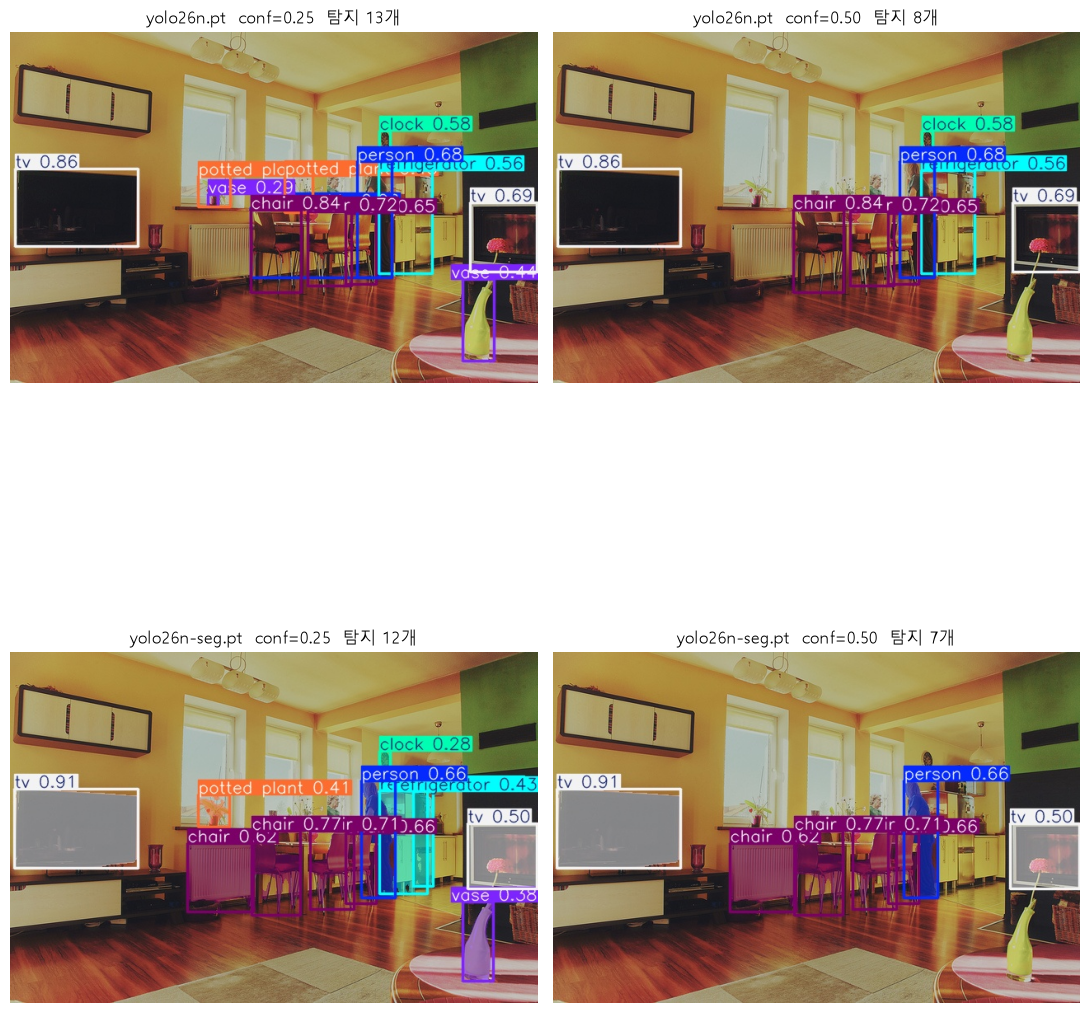

저장: outputs/yolo/comparison__coco_000000000139.png


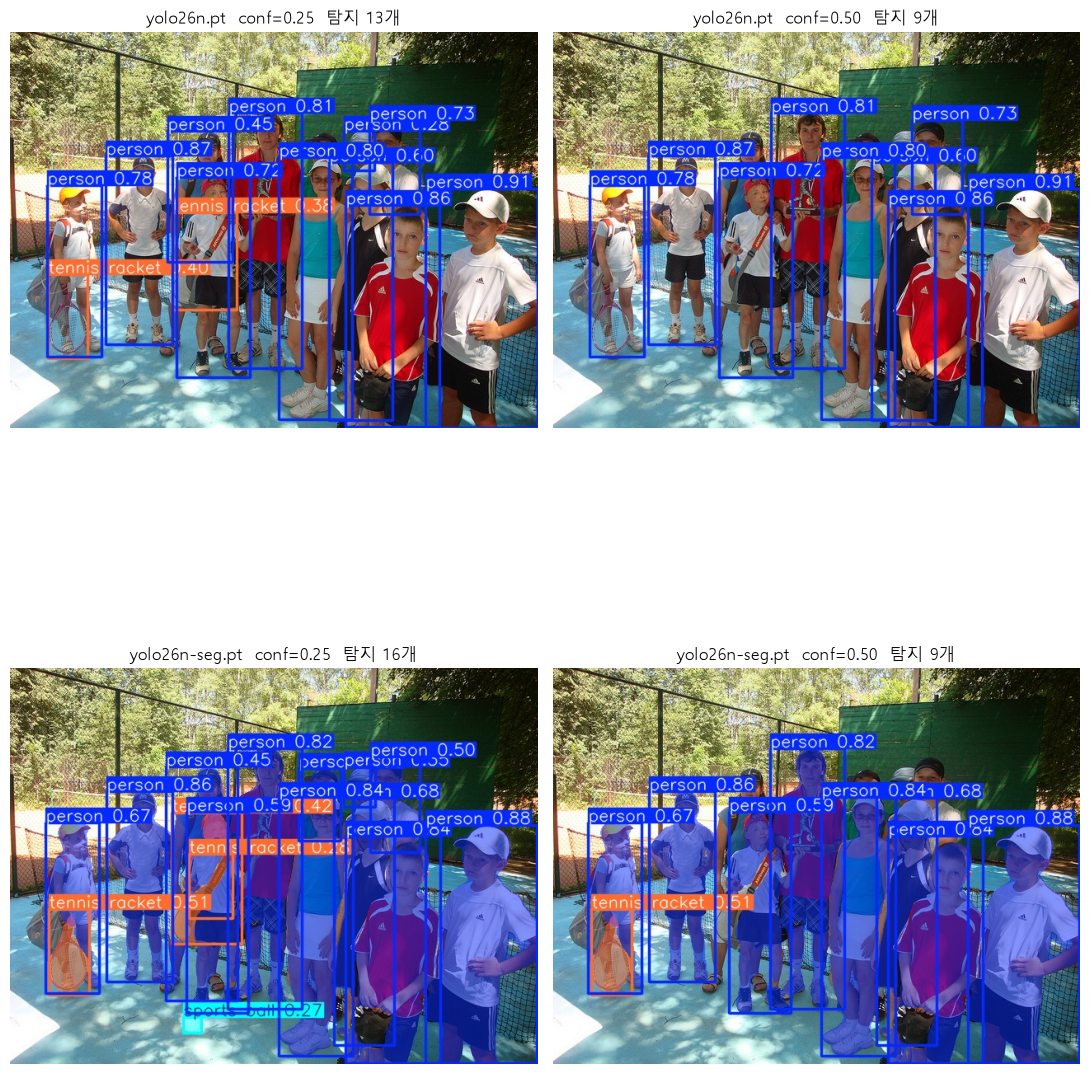

저장: outputs/yolo/comparison__coco_000000001000.png


In [7]:
for img in images:
    fig, axes = plt.subplots(2, 2, figsize=(11, 15))
    for ri, kind in enumerate(MODELS):
        for ci, conf in enumerate(CONFS):
            run = runs[(img.name, kind, conf)]
            im = cv2.cvtColor(cv2.imread(str(OUT / "images" / f"{run['stem']}.jpg")), cv2.COLOR_BGR2RGB)
            ax = axes[ri][ci]
            ax.imshow(im)
            ax.set_title(f"{MODELS[kind]}  conf={conf:.2f}  탐지 {len(run['dets'])}개")
            ax.axis("off")
    plt.tight_layout()
    cmp_path = OUT / f"comparison__{img.stem}.png"
    plt.savefig(cmp_path, dpi=110)
    plt.show()
    print("저장:", rel(cmp_path))

## 7. 원본 대조와 검토 기록

모델 결과를 믿기 전에, **저장된 JSON·마스크 파일만으로 원본 사진 위에 다시 그려** 위치가 맞는지 확인합니다
(`outputs/yolo/verify/`). 그리고 탐지마다 아래를 검사해 `outputs/yolo/review.csv` 에 남깁니다.

| 검사 | 확인 필요로 표시하는 조건 |
|---|---|
| 원본 범위 | 박스가 사진 밖으로 나가거나 뒤집힘 |
| 낮은 점수 | 점수 < 0.50 (conf=0.25 에서만 잡힌 것) |
| 가장자리 | 박스가 사진 가장자리 2px 이내에 닿음 (일부만 보이는 대상일 수 있음) |
| 작은 대상 | 박스 넓이가 사진의 0.5% 미만 |
| 마스크-박스 | seg 마스크의 바깥 사각형과 박스의 겹침(IoU)이 0.7 미만 |
| 두 모델 불일치 | 같은 conf에서 다른 모델이 같은 클래스·IoU 0.5 이상으로 못 찾음 |

이 검사들은 **정답 라벨이 없을 때 쓸 수 있는 의심 신호**일 뿐, 맞았는지 틀렸는지를 알려 주지는 않습니다.

In [8]:
review = []
rng = np.random.default_rng(0)
for img in images:
    orig = cv2.imread(str(img))
    H, W = orig.shape[:2]
    for kind in MODELS:
        other = "seg" if kind == "det" else "det"
        for conf in CONFS:
            stem = runs[(img.name, kind, conf)]["stem"]
            doc = json.loads((OUT / "json" / f"{stem}.json").read_text(encoding="utf-8"))   # 저장된 파일에서 다시 읽음
            canvas = orig.copy()
            overlay = orig.copy()
            for d in doc["detections"]:
                x1, y1, x2, y2 = d["box_xyxy"]
                color = tuple(int(c) for c in rng.integers(60, 255, 3))
                mask_iou = None
                if "mask_file" in d:
                    m = cv2.imread(str(ROOT / d["mask_file"]), cv2.IMREAD_GRAYSCALE)
                    overlay[m > 0] = color
                    ys, xs = np.where(m > 0)
                    if len(xs):
                        mask_iou = round(iou([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1], d["box_xyxy"]), 3)
                    else:
                        mask_iou = 0.0
                cv2.rectangle(canvas, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
                cv2.putText(canvas, f"#{d['id']} {d['class_name']} {d['score']:.2f}", (int(x1), max(15, int(y1) - 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

                reasons = []
                in_range = (0 <= x1 < x2 <= W) and (0 <= y1 < y2 <= H)
                if not in_range:
                    reasons.append("박스가 원본 범위를 벗어남")
                if d["score"] < 0.50:
                    reasons.append("낮은 점수(<0.50)")
                if x1 <= 2 or y1 <= 2 or x2 >= W - 2 or y2 >= H - 2:
                    reasons.append("사진 가장자리에 닿음")
                if (x2 - x1) * (y2 - y1) < 0.005 * W * H:
                    reasons.append("작은 대상")
                if mask_iou is not None and mask_iou < 0.7:
                    reasons.append(f"마스크-박스 겹침 낮음({mask_iou})")
                peers = runs[(img.name, other, conf)]["dets"]
                if not any(p["class_id"] == d["class_id"] and iou(d["box_xyxy"], p["box_xyxy"]) >= 0.5 for p in peers):
                    reasons.append(f"{MODELS[other]} 에서 못 찾음")

                review.append({
                    "image": img.name, "model": MODELS[kind], "conf": conf, "id": d["id"],
                    "class": d["class_name"], "score": d["score"], "box_xyxy": d["box_xyxy"],
                    "원본범위_안": in_range, "mask_box_iou": mask_iou,
                    "확인필요": bool(reasons), "사유": "; ".join(reasons),
                    "수정내역": "없음 (좌표는 소수 첫째 자리 반올림만 적용)",
                    "근거파일": f"json/{stem}.json" + (f", {d['mask_file'].split('outputs/yolo/')[-1]}" if "mask_file" in d else ""),
                })
            blended = cv2.addWeighted(overlay, 0.45, canvas, 0.55, 0) if kind == "seg" else canvas
            cv2.imwrite(str(OUT / "verify" / f"{stem}__from_json.jpg"), blended)

review_df = pd.DataFrame(review)
review_df.to_csv(OUT / "review.csv", index=False, encoding="utf-8-sig")
print("검토 행:", len(review_df), "/ 확인 필요:", int(review_df["확인필요"].sum()), "/ 원본 범위 밖:", int((~review_df["원본범위_안"]).sum()))
display(review_df[review_df["conf"] == 0.25].drop(columns=["수정내역", "근거파일", "conf", "원본범위_안"]))

검토 행: 107 / 확인 필요: 50 / 원본 범위 밖: 0


,image,model,id,class,score,box_xyxy,mask_box_iou,확인필요,사유
0,bus.jpg,yolo26n.pt,0,bus,0.8806,"[0.0, 230.5, 803.2, 750.7]",NaN,True,사진 가장자리에 닿음
1,bus.jpg,yolo26n.pt,1,person,0.8720,"[48.6, 397.7, 240.3, 902.4]",NaN,False,
2,bus.jpg,yolo26n.pt,2,person,0.8608,"[222.9, 404.8, 345.5, 861.0]",NaN,False,
3,bus.jpg,yolo26n.pt,3,person,0.8462,"[669.6, 394.5, 809.9, 879.4]",NaN,True,사진 가장자리에 닿음
4,bus.jpg,yolo26n.pt,4,person,0.6562,"[0.2, 553.0, 59.7, 871.3]",NaN,True,사진 가장자리에 닿음
...,...,...,...,...,...,...,...,...,...
93,coco_000000001000.jpg,yolo26n-seg.pt,11,tennis racket,0.4166,"[196.2, 175.5, 281.9, 334.5]",0.983,True,낮은 점수(<0.50)
94,coco_000000001000.jpg,yolo26n-seg.pt,12,person,0.3509,"[406.0, 119.0, 443.2, 168.8]",0.956,True,낮은 점수(<0.50)
95,coco_000000001000.jpg,yolo26n-seg.pt,13,person,0.2990,"[350.7, 121.5, 401.6, 209.9]",0.980,True,낮은 점수(<0.50); yolo26n.pt 에서 못 찾음
96,coco_000000001000.jpg,yolo26n-seg.pt,14,tennis racket,0.2756,"[217.6, 225.7, 271.0, 303.5]",0.982,True,낮은 점수(<0.50); yolo26n.pt 에서 못 찾음


### 눈으로 대조한 기록 — 샘플 3장 한정 (자동 생성이 아니라 사람이 `verify/` 이미지를 보고 적은 것)

**`bus.jpg` (810×1080)**
- 두 모델의 박스 5개(bus 1, person 4)가 원본의 버스 한 대와 사람 네 명 위에 놓임. 저장된 JSON·마스크 파일만으로 다시 그린 `verify/` 이미지에서도 같은 위치.
- 이 사진의 `확인필요` 10건은 전부 사유가 "사진 가장자리에 닿음" 하나. 버스와 양쪽 끝 사람이 사진 밖으로 잘려 있어 박스가 실제보다 작을 수 있음(추정, 확인 불가).
- conf 0.25와 0.50 결과가 같음(가장 낮은 점수 0.65). 이 사진만으로는 conf 효과를 볼 수 없어 아래 두 장을 추가함.

**`coco_000000000139.jpg` (640×426, 실내)** — conf 0.25→0.50: yolo26n 13→8개, yolo26n-seg 12→7개
- 0.50에서 사라진 것은 모두 점수 0.50 미만(코드로 검사). 그중 오른쪽 아래의 노란 꽃병(vase 0.44)은 실제로 꽃병이 있어 **점수가 낮아도 맞은 사례**였음 → conf 를 올리면 맞는 것도 잃을 수 있음.
- 오른쪽의 벽난로처럼 보이는 물체가 tv(0.69, seg 는 0.50)로 잡힘. 내 눈에는 TV로 단정하기 어렵지만 확신 못 함(미확인). 점수가 0.50 이상이라 conf 를 올려도 남음 → conf 를 올린다고 틀린 탐지가 다 걸러지지는 않음.

**`coco_000000001000.jpg` (640×480, 테니스 아이들)** — conf 0.25→0.50: yolo26n 13→9개, yolo26n-seg 16→9개
- seg 에서만 잡힌 sports ball 0.27 은 해당 위치(왼쪽 아래 작은 상자)에 내 눈에는 공으로 보이는 것이 없음. 오탐일 가능성이 높지만 작아서 확정 못 함. 0.50에서 사라짐.
- 라켓을 든 아이 쪽의 tennis racket 0.40·0.42 는 위치가 맞아 보임. 이것도 0.50에서 사라짐.
- 사람이 겹쳐 있어 중복 탐지나 누락을 정확히 세지 못함(미확인).

**공통**
- 전체 검토 107행 중 `확인필요` 50행(`review.csv`). 모델 결과를 고치거나 지운 것은 없고, 박스 좌표 소수 첫째 자리 반올림과 마스크 채우기(윤곽선→PNG)만 적용.
- 점수가 낮은 것이 틀렸다는 뜻도, 높은 것이 맞았다는 뜻도 아님. 정답 라벨이 없어 맞고 틀림은 위처럼 눈으로만 판단했고, 사진 3장이라 일반화할 수 없음.
- `verify/` 이미지는 탐지가 많으면 글씨가 겹쳐 읽기 어려움. 정확한 값은 `review.csv` 와 `json/` 을 볼 것.
- 개발 중 1회 확인: 내보낸 `outputs/yolo/code/yolo_service_code.py` 를 별도 폴더에서 실행하니 JSON 12개와 마스크 54개가 이 실행 결과와 완전히 같았음(노트북이 스스로 검사하는 것은 아님).

## 8. 처리 범위 (무엇을 했고, 무엇은 못 했는가)

아래 표는 코드가 직접 센 값이고, 그 아래 목록은 이 노트북이 **하지 않은 것**입니다.

In [9]:
scope = []
for img in images:
    for kind in MODELS:
        for conf in CONFS:
            n = len(runs[(img.name, kind, conf)]["dets"])
            scope.append({"image": img.name, "model": MODELS[kind], "conf": conf, "탐지수": n,
                          "비고": "탐지 0개 — 대상이 없다는 뜻이 아니라 이 설정에서 못 찾았다는 뜻" if n == 0 else ""})
display(pd.DataFrame(scope))
print("처리한 사진 수:", len(images), "| 읽기 실패로 건너뛴 사진: 위 4번 칸 출력 참고")
print("두 모델이 아는 클래스 수:", {MODELS[k]: len(models[k].names) for k in MODELS})
if not dropped_rows:
    print("[주의] conf 를 0.25 -> 0.50 으로 올려도 사라진 탐지가 없음: 이 입력에서는 두 설정의 결과가 같아, "
          "'낮은 점수' 검사와 conf 비교 효과는 실제로 시험되지 않았음. 다른 사진을 inputs/ 에 넣어 확인 필요.")

,image,model,conf,탐지수,비고
0,bus.jpg,yolo26n.pt,0.25,5,
1,bus.jpg,yolo26n.pt,0.50,5,
2,bus.jpg,yolo26n-seg.pt,0.25,5,
3,bus.jpg,yolo26n-seg.pt,0.50,5,
4,coco_000000000139.jpg,yolo26n.pt,0.25,13,
5,coco_000000000139.jpg,yolo26n.pt,0.50,8,
6,coco_000000000139.jpg,yolo26n-seg.pt,0.25,12,
7,coco_000000000139.jpg,yolo26n-seg.pt,0.50,7,
8,coco_000000001000.jpg,yolo26n.pt,0.25,13,
9,coco_000000001000.jpg,yolo26n.pt,0.50,9,


처리한 사진 수: 3 | 읽기 실패로 건너뛴 사진: 위 4번 칸 출력 참고
두 모델이 아는 클래스 수: {'yolo26n.pt': 80, 'yolo26n-seg.pt': 80}


**이 결과로 말할 수 없는 것**

- **정확도**: 정답 라벨(사람이 달아 둔 박스)이 없어서 "맞게 찾았는가", "놓친 것은 없는가"는 계산하지 않았습니다. 점수는 모델이 스스로 매긴 확신도일 뿐 정답률이 아닙니다.
- **클래스 범위**: 이 모델은 COCO 80개 클래스만 압니다. 사진에 있어도 그 목록에 없으면 찾지 못합니다(실패가 아니라 모델의 범위).
- **마스크 품질**: 마스크는 모델이 준 윤곽선을 원본 크기에 채운 것이라 가장자리가 거칩니다. 면적(`mask_area_px`)과 박스 겹침(IoU)만 점검했고, 윤곽이 실제 물체와 맞는지는 사람이 눈으로 봐야 합니다.
- **일반화**: 사진이 적으면(기본은 샘플 3장) 모델 간 우열을 말할 수 없습니다. 이 노트북은 재실행 때 값이 같은지를 스스로 검사하지 않습니다(개발 중에 한 번 비교한 결과는 아래 눈으로 대조한 기록 칸).
- **시간(ms)**: 첫 호출이 느린 워밍업 영향이 섞여 있어 성능 비교용 값이 아닙니다.

## 9. 실행 코드 저장 + manifest.json

In [10]:
# 이 노트북의 코드 셀을 .py 로 내보내 outputs/yolo/code/ 에 보관 (노트북 파일이 디스크에 있을 때)
nb_path = ROOT / "yolo_service.ipynb"
code_path = OUT / "code" / "yolo_service_code.py"
nbj = json.loads(nb_path.read_text(encoding="utf-8"))
chunks = ["".join(c["source"]) for c in nbj["cells"] if c["cell_type"] == "code"]
code_path.write_text("# yolo_service.ipynb 의 코드 셀을 순서대로 이어 붙인 사본 (이 폴더에서 python 으로 실행 가능)\n\n"
                     + "\n\n# ----- 다음 셀 -----\n\n".join(chunks).replace("display(", "print(") + "\n", encoding="utf-8")

outputs = sorted(p for p in OUT.rglob("*") if p.is_file() and p.name != "manifest.json")
manifest = {
    "created_at": RUN_STARTED,
    "finished_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "run_location": env["run_location"],
    "environment": env,
    "settings": {"imgsz": IMGSZ, "device": DEVICE, "conf": list(CONFS)},
    "models": model_info,
    "inputs": input_info,
    "code": {"notebook": rel(nb_path), "code_copy": rel(code_path), "code_copy_sha256": sha256(code_path)},
    "results_summary": {"images_processed": len(images),
                        "detections": {f"{MODELS[k]}@{c}": sum(len(runs[(i.name, k, c)]['dets']) for i in images)
                                       for k in MODELS for c in CONFS},
                        "review_rows": int(len(review_df)), "review_needs_check": int(review_df["확인필요"].sum())},
    "outputs": [{"file": rel(p), "bytes": p.stat().st_size} for p in outputs],
    "limitations": "정답 라벨 없음: 정확도 미평가. COCO 80 클래스 범위. 자세한 내용은 노트북 8번 칸.",
}
(OUT / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("manifest.json 저장 | 출력 파일", len(outputs), "개")
print(json.dumps(manifest["results_summary"], ensure_ascii=False, indent=2))

manifest.json 저장 | 출력 파일 95 개
{
  "images_processed": 3,
  "detections": {
    "yolo26n.pt@0.25": 31,
    "yolo26n.pt@0.5": 22,
    "yolo26n-seg.pt@0.25": 33,
    "yolo26n-seg.pt@0.5": 21
  },
  "review_rows": 107,
  "review_needs_check": 50
}
